<a href="https://colab.research.google.com/github/sterlingconsultants/Marine-Science/blob/main/Exploratory_Topic_Modelling_of_Marine_Science_Literature.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip -q install requests pandas numpy matplotlib seaborn tqdm pymupdf nltk scikit-learn

import os
import re
import json
import time
import requests
import pandas as pd
import numpy as np

from google.colab import drive
from tqdm.auto import tqdm
from pathlib import Path

# from collections import Counter

import nltk

nltk.download("stopwords")

!pip install gensim
from nltk.corpus import stopwords
from gensim.utils import simple_preprocess
from gensim import corpora

!pip install -q wordcloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

!pip install -q bertopic sentence-transformers umap-learn hdbscan

!pip install huggingface_hub
from huggingface_hub import notebook_login

notebook_login()

from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

print("Python environment ready.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Python environment ready.


In [10]:
import spacy
from nltk.stem import WordNetLemmatizer

In [11]:
OPENALEX_URL = "https://api.openalex.org/works"

START_YEAR = 2015
END_YEAR = 2026

SEARCH_TERMS = [
    "marine science",
    "marine ecology",
    "marine biology",
    "oceanography",
    "coral reef",
    "marine biodiversity",
    "marine conservation",
    "marine pollution",
    "marine ecosystem",
    "fisheries",
    "ocean climate",
    "ocean acidification",
    "marine turtles",
    "microplastics",
    "eDNA",
    "underwater acoustics",
    "marine remote sensing",
    "algae",
    "environment DNA",

]

In [12]:
# ============================================================
# STEP 2 — OPENALEX SEARCH FUNCTION
# ============================================================

def search_openalex(
    search_term,
    start_year=2015,
    end_year=2026,
    per_page=200
):

    params = {
        "search": search_term,
        "filter": (
            f"from_publication_date:"
            f"{start_year}-01-01,"
            f"to_publication_date:"
            f"{end_year}-12-31"
        ),
        "per-page": per_page
    }

    response = requests.get(
        OPENALEX_URL,
        params=params,
        timeout=60
    )

    response.raise_for_status()

    return response.json()

In [13]:
# ============================================================
# STEP 3 — EXTRACT OPENALEX RECORDS
# ============================================================

def extract_openalex_record(
    work,
    search_term
):

    authors = []

    for authorship in work.get(
        "authorships",
        []
    ):

        author = authorship.get(
            "author"
        )

        if author:

            name = author.get(
                "display_name"
            )

            if name:
                authors.append(name)

    primary_location = (
        work.get("primary_location")
        or {}
    )

    source = (
        primary_location.get("source")
        or {}
    )

    best_oa_location = (
        work.get("best_oa_location")
        or {}
    )

    return {

        "openalex_id":
            work.get("id"),

        "doi":
            work.get("doi"),

        "title":
            work.get("title"),

        "authors":
            authors,

        "author_count":
            len(authors),

        "publication_year":
            work.get("publication_year"),

        "publication_date":
            work.get("publication_date"),

        "journal":
            source.get("display_name"),

        "publisher":
            (
                source
                .get("host_organization_name")
            ),

        "volume":
            work.get("biblio", {})
                .get("volume"),

        "issue":
            work.get("biblio", {})
                .get("issue"),

        "first_page":
            work.get("biblio", {})
                .get("first_page"),

        "last_page":
            work.get("biblio", {})
                .get("last_page"),

        "article_number":
            work.get("biblio", {})
                .get("article_number"),

        "cited_by_count":
            work.get("cited_by_count"),

        "is_oa":
            work.get("open_access", {})
                .get("is_oa"),

        "oa_status":
            work.get("open_access", {})
                .get("oa_status"),

        "oa_url":
            work.get("open_access", {})
                .get("oa_url"),

        "best_oa_url":
            best_oa_location.get(
                "landing_page_url"
            ),

        "pdf_url":
            best_oa_location.get(
                "pdf_url"
            ),

        "search_term":
            search_term
    }

In [14]:
# ============================================================
# STEP 4 — RETRIEVE ALL SEARCH RESULTS
# ============================================================

all_records = []

#for search_term in SEARCH_TERMS:
for search_term in SEARCH_TERMS:

    print(
        f"Searching OpenAlex: {search_term}"
    )

    try:

        data = search_openalex(
            search_term,
            START_YEAR,
            END_YEAR
        )

        for work in data.get(
            "results",
            []
        ):

            record = extract_openalex_record(
                work,
                search_term
            )

            all_records.append(record)

        time.sleep(0.2)

    except Exception as e:

        print(
            f"Error for {search_term}: {e}"
        )


openalex_raw = pd.DataFrame(
    all_records
)

print(
    "Records retrieved:",
    len(openalex_raw)
)

Searching OpenAlex: marine science
Searching OpenAlex: marine ecology
Searching OpenAlex: marine biology
Searching OpenAlex: oceanography
Searching OpenAlex: coral reef
Searching OpenAlex: marine biodiversity
Searching OpenAlex: marine conservation
Searching OpenAlex: marine pollution
Searching OpenAlex: marine ecosystem
Searching OpenAlex: fisheries
Searching OpenAlex: ocean climate
Searching OpenAlex: ocean acidification
Searching OpenAlex: marine turtles
Searching OpenAlex: microplastics
Searching OpenAlex: eDNA
Searching OpenAlex: underwater acoustics
Searching OpenAlex: marine remote sensing
Searching OpenAlex: algae
Searching OpenAlex: environment DNA
Records retrieved: 3800


In [15]:
# ============================================================
# STEP 5 — DEDUPLICATION
# ============================================================

def normalise_doi(doi):

    if pd.isna(doi) or not doi:
        return ""

    doi = str(doi).strip().lower()

    doi = re.sub(
        r"^https?://(dx\.)?doi\.org/",
        "",
        doi
    )

    return doi.strip()


def normalise_title(title):

    if pd.isna(title):
        return ""

    title = str(title).lower()

    title = re.sub(
        r"[^a-z0-9\s]",
        " ",
        title
    )

    title = re.sub(
        r"\s+",
        " ",
        title
    ).strip()

    return title


openalex_raw["doi_normalised"] = (
    openalex_raw["doi"]
    .apply(normalise_doi)
)

openalex_raw["title_normalised"] = (
    openalex_raw["title"]
    .apply(normalise_title)
)


# DOI deduplication
with_doi = openalex_raw[
    openalex_raw["doi_normalised"] != ""
].drop_duplicates(
    subset="doi_normalised"
)


# Records without DOI
without_doi = openalex_raw[
    openalex_raw["doi_normalised"] == ""
].drop_duplicates(
    subset="title_normalised"
)


corpus = pd.concat(
    [
        with_doi,
        without_doi
    ],
    ignore_index=True
)


# Final title-level protection
corpus = corpus.drop_duplicates(
    subset="title_normalised"
).reset_index(drop=True)


print(
    "Unique documents:",
    len(corpus)
)

Unique documents: 3371


In [16]:
# ============================================================
# STEP 6 — Create DOI and paper URLs
# ============================================================

def make_doi_url(doi):

    if pd.isna(doi) or not doi:
        return None

    doi = str(doi).strip()

    doi = re.sub(
        r"^https?://(dx\.)?doi\.org/",
        "",
        doi,
        flags=re.IGNORECASE
    )

    return f"https://doi.org/{doi}"


corpus["doi_url"] = (
    corpus["doi"]
    .apply(make_doi_url)
)

corpus["paper_url"] = (
    corpus["doi_url"]
)

corpus.loc[
    corpus["paper_url"].isna(),
    "paper_url"
] = corpus.loc[
    corpus["paper_url"].isna(),
    "best_oa_url"
]

In [17]:
#======================================
# Step 7 author-formatting code with this more robust version
#========================================

def format_authors(value):
    # Handle None / missing values
    if value is None:
        return ""

    # Handle strings
    if isinstance(value, str):
        return value.strip()

    # Handle lists, tuples, NumPy arrays, etc.
    if isinstance(value, (list, tuple, np.ndarray)):
        authors = []

        for author in value:
            if author is None:
                continue

            # Convert individual author values to strings
            author = str(author).strip()

            if author:
                authors.append(author)

        return "; ".join(authors)

    # Handle scalar missing values safely
    try:
        if pd.isna(value):
            return ""
    except (TypeError, ValueError):
        pass

    return str(value).strip()


corpus["author_names"] = corpus["authors"].apply(format_authors)

print("Author formatting complete.")
print(corpus["author_names"].head(10))

Author formatting complete.
0                                   Michael J. Kennish
1                                    David W. Johnston
2                                                     
3    Ketil Malde; Nils Olav Handegard; Line Eikvil;...
4    Lionel Guidi; Fernàndez-Guerra, Antonio; Bakke...
5                                                     
6                                                     
7                                                     
8                      Cigdem Beyan; Howard I. Browman
9                                                     
Name: author_names, dtype: object


In [18]:
print("Column dtype:", corpus["authors"].dtype)

print("\nExamples of author values:")
for i, value in corpus["authors"].head(10).items():
    print(i, type(value), value)

Column dtype: object

Examples of author values:
0 <class 'list'> ['Michael J. Kennish']
1 <class 'list'> ['David W. Johnston']
2 <class 'list'> []
3 <class 'list'> ['Ketil Malde', 'Nils Olav Handegard', 'Line Eikvil', 'Arnt-Børre Salberg']
4 <class 'list'> ['Lionel Guidi', 'Fernàndez-Guerra, Antonio', 'Bakker, Dorothee', 'Canchaya, Carlos', 'Curry, Edward', 'Foglini, Federica', 'Irission, Jean-Olivier', 'Malde, Ketil', 'Marshall, C. Tara', 'Obst, Matthias', 'Ribeiro, Rita P.', 'Tjiputra, Jerry']
5 <class 'list'> []
6 <class 'list'> []
7 <class 'list'> []
8 <class 'list'> ['Cigdem Beyan', 'Howard I. Browman']
9 <class 'list'> []


In [19]:
# Checking whether authors are formatted as lists, strings, or dictionaries.
from collections import Counter

author_types = Counter(type(x).__name__ for x in corpus["authors"])

print(author_types)

Counter({'list': 3371})


In [20]:
print(corpus.columns.tolist())

['openalex_id', 'doi', 'title', 'authors', 'author_count', 'publication_year', 'publication_date', 'journal', 'publisher', 'volume', 'issue', 'first_page', 'last_page', 'article_number', 'cited_by_count', 'is_oa', 'oa_status', 'oa_url', 'best_oa_url', 'pdf_url', 'search_term', 'doi_normalised', 'title_normalised', 'doi_url', 'paper_url', 'author_names']


In [21]:
available_columns = [
    col for col in ["paper_id", "openalex_id", "title", "author_names"]
    if col in corpus.columns
]

print("Available columns:", available_columns)

display(corpus[available_columns].head(10))

Available columns: ['openalex_id', 'title', 'author_names']


,openalex_id,title,author_names
0,https://openalex.org/W1993512136,Practical Handbook of Marine Science,Michael J. Kennish
1,https://openalex.org/W2884132865,Unoccupied Aircraft Systems in Marine Science ...,David W. Johnston
2,https://openalex.org/W4232999154,Frontiers in Marine Science,
3,https://openalex.org/W3016465642,Machine intelligence and the data-driven futur...,Ketil Malde; Nils Olav Handegard; Line Eikvil;...
4,https://openalex.org/W4366342697,Big Data in Marine Science,"Lionel Guidi; Fernàndez-Guerra, Antonio; Bakke..."
5,https://openalex.org/W4298303828,Indian Journal of Geo-Marine Sciences,
6,https://openalex.org/W4239681756,Annals of Marine Science,
7,https://openalex.org/W603264994,Annual Review of Marine Science,
8,https://openalex.org/W3036672024,Setting the stage for the machine intelligence...,Cigdem Beyan; Howard I. Browman
9,https://openalex.org/W4403377110,World Journal of Fish and Marine Sciences,


In [22]:
# Create a new variable paper_id
if "paper_id" not in corpus.columns:
    if "openalex_id" in corpus.columns:
        corpus["paper_id"] = corpus["openalex_id"]
    else:
        corpus["paper_id"] = range(1, len(corpus) + 1)

print("paper_id created.")

paper_id created.


In [23]:
display(
    corpus[
        ["paper_id", "title", "author_names"]
    ].head(10)
)

,paper_id,title,author_names
0,https://openalex.org/W1993512136,Practical Handbook of Marine Science,Michael J. Kennish
1,https://openalex.org/W2884132865,Unoccupied Aircraft Systems in Marine Science ...,David W. Johnston
2,https://openalex.org/W4232999154,Frontiers in Marine Science,
3,https://openalex.org/W3016465642,Machine intelligence and the data-driven futur...,Ketil Malde; Nils Olav Handegard; Line Eikvil;...
4,https://openalex.org/W4366342697,Big Data in Marine Science,"Lionel Guidi; Fernàndez-Guerra, Antonio; Bakke..."
5,https://openalex.org/W4298303828,Indian Journal of Geo-Marine Sciences,
6,https://openalex.org/W4239681756,Annals of Marine Science,
7,https://openalex.org/W603264994,Annual Review of Marine Science,
8,https://openalex.org/W3036672024,Setting the stage for the machine intelligence...,Cigdem Beyan; Howard I. Browman
9,https://openalex.org/W4403377110,World Journal of Fish and Marine Sciences,


In [24]:
# Create a stable paper ID if it doesn't already exist
if "paper_id" not in corpus.columns:
    corpus["paper_id"] = range(1, len(corpus) + 1)

# Make sure author_names exists
if "author_names" not in corpus.columns:
    corpus["author_names"] = corpus["authors"].apply(format_authors)

print(f"Corpus contains {len(corpus)} documents.")
print(f"Columns: {len(corpus.columns)}")

display(
    corpus[
        ["paper_id", "openalex_id", "title", "author_names"]
    ].head(10)
)

Corpus contains 3371 documents.
Columns: 27


,paper_id,openalex_id,title,author_names
0,https://openalex.org/W1993512136,https://openalex.org/W1993512136,Practical Handbook of Marine Science,Michael J. Kennish
1,https://openalex.org/W2884132865,https://openalex.org/W2884132865,Unoccupied Aircraft Systems in Marine Science ...,David W. Johnston
2,https://openalex.org/W4232999154,https://openalex.org/W4232999154,Frontiers in Marine Science,
3,https://openalex.org/W3016465642,https://openalex.org/W3016465642,Machine intelligence and the data-driven futur...,Ketil Malde; Nils Olav Handegard; Line Eikvil;...
4,https://openalex.org/W4366342697,https://openalex.org/W4366342697,Big Data in Marine Science,"Lionel Guidi; Fernàndez-Guerra, Antonio; Bakke..."
5,https://openalex.org/W4298303828,https://openalex.org/W4298303828,Indian Journal of Geo-Marine Sciences,
6,https://openalex.org/W4239681756,https://openalex.org/W4239681756,Annals of Marine Science,
7,https://openalex.org/W603264994,https://openalex.org/W603264994,Annual Review of Marine Science,
8,https://openalex.org/W3036672024,https://openalex.org/W3036672024,Setting the stage for the machine intelligence...,Cigdem Beyan; Howard I. Browman
9,https://openalex.org/W4403377110,https://openalex.org/W4403377110,World Journal of Fish and Marine Sciences,


In [25]:
# ============================================================
# STEP 8 — SAVE MASTER CORPUS
# ============================================================

DATA_DIR = "/content/marine_literature/data"

os.makedirs(
    DATA_DIR,
    exist_ok=True
)

MASTER_FILE = os.path.join(
    DATA_DIR,
    "marine_science_master_corpus.csv"
)

corpus.to_csv(
    MASTER_FILE,
    index=False
)

print(
    "Saved:",
    MASTER_FILE
)

Saved: /content/marine_literature/data/marine_science_master_corpus.csv


In [26]:
corpus = pd.read_csv(MASTER_FILE)

print("Number of documents:", len(corpus))
print("Number of columns:", len(corpus.columns))

Number of documents: 3371
Number of columns: 27


In [27]:
# ============================================================
# STEP 9 — DOCUMENT TYPE CLASSIFICATION
# ============================================================

document_type_patterns = {
    "review": r"\breview\b|\breviews\b|\bsynthesis\b|\bmeta-analysis\b|\bsystematic review\b",
    "methods": r"\bmethods?\b|\bmethodology\b|\bprotocol\b|\bprocedure\b|\btechnique\b|\bstatistical\b|\bmachine learning\b",
    "mapping": r"\bmap\b|\bmapping\b|\bmaps\b",
    "software": r"\bsoftware\b|\bpackage\b|\btool\b",
    "model": r"\bmodel\b|\bmodels\b|\bmodelling\b|\bmodeling\b|\bstatistical\b|\bmachine learning\b",
    "guidelines": r"\bguideline\b|\bguidelines\b|\brecommendations\b",
    "book_chapter": r"\bchapter\b",
    "statistics": r"\bF score\b|\bregression\b|\bbayesian\b|\brandom forest\b|\bhierarchical"
}

for category, pattern in document_type_patterns.items():
    corpus[category] = (
        corpus["title"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            regex=True
        )
    )

# Primary classification
def classify_document(row):

    if row["book_chapter"]:
        return "book_chapter"
    elif row["guidelines"]:
        return "guidelines"
    elif row["software"]:
        return "software"
    elif row["review"]:
        return "review"
    elif row["methods"]:
        return "methods"
    elif row["mapping"]:
        return "mapping"
    elif row["model"]:
        return "model"
    elif row["statistics"]:
        return "statistics"
    else:
        return "research_article"


corpus["document_type"] = corpus.apply(
    classify_document,
    axis=1
)

document_type_summary = (
    corpus["document_type"]
    .value_counts()
    .rename_axis("document_type")
    .reset_index(name="count")
)

document_type_summary["percentage"] = (
    document_type_summary["count"]
    / len(corpus)
    * 100
).round(1)

display(document_type_summary)

,document_type,count,percentage
0,research_article,3023,89.7
1,review,147,4.4
2,methods,81,2.4
3,model,62,1.8
4,software,25,0.7
5,mapping,23,0.7
6,guidelines,4,0.1
7,book_chapter,3,0.1
8,statistics,3,0.1


In [29]:

corpus["screening_decision"] = "include"
corpus["screening_reason"] = ""
corpus["screening_notes"] = ""

In [30]:
# ============================================================
# STEP 10 — FINAL MODELLING CORPUS
# ============================================================

analysis_corpus = corpus[
    corpus["screening_decision"]
    .str.lower()
    .eq("include")
].copy()

analysis_corpus = analysis_corpus.reset_index(drop=True)

print("Final modelling documents:", len(analysis_corpus))

Final modelling documents: 3371


In [31]:
# ============================================================
# STEP 11 — BUILD TOPIC-MODELLING TEXT
# ============================================================

TEXT_COLUMNS = [
    "title",
    "abstract",
    "introduction",
    "methods",
    "results",
    "discussion"
]

for column in TEXT_COLUMNS:
    if column not in analysis_corpus.columns:
        analysis_corpus[column] = ""

analysis_corpus[TEXT_COLUMNS] = (
    analysis_corpus[TEXT_COLUMNS]
    .fillna("")
)

analysis_corpus["topic_text"] = (
    analysis_corpus[TEXT_COLUMNS]
    .astype(str)
    .agg(" ".join, axis=1)
)

print(
    "Documents with topic text:",
    (analysis_corpus["topic_text"].str.len() > 0).sum()
)

Documents with topic text: 3371


In [32]:
# ============================================================
# STEP 12 — CLEAN AND TOKENISE
# ============================================================

import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords
from gensim.utils import simple_preprocess
from gensim import corpora

english_stopwords = set(
    stopwords.words("english")
)

MARINE_GENERIC_STOPWORDS = {
    "study",
    "studies",
    "paper",
    "research",
    "result",
    "results",
    "method",
    "methods",
    "analysis",
    "analyses",
    "data",
    "dataset",
    "sample",
    "samples",
    "significant",
    "significantly",
    "observed",
    "using",
    "used",
    "use,",
    "based",
    "showed",
    "shows",
    "shown",
    "found",
    "findings",
    "different",
    "differences",
    "effect",
    "effects",
    "associated",
    "according",
    "number",
    "total",
    "high",
    "higher",
    "low",
    "lower",
    "fig",
    "figure",
    "table",
    "tables",
    "supplementary",
    "supplement",
    "confidence",
    "et",
    "al"
}

ALL_STOPWORDS = (
    english_stopwords
    | MARINE_GENERIC_STOPWORDS
)


def clean_topic_text(text):

    if not text:
        return ""

    text = str(text).lower()

    # URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Email addresses
    text = re.sub(
        r"\S+@\S+",
        " ",
        text
    )

    # Remove non-letter characters
    text = re.sub(
        r"[^a-z\s]",
        " ",
        text
    )

    # Remove one-character tokens
    text = re.sub(
        r"\b[a-z]\b",
        " ",
        text
    )

    # Normalise whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    words = [
        word
        for word in text.split()
        if word not in ALL_STOPWORDS
        and len(word) > 2
    ]

    return " ".join(words)


analysis_corpus["topic_text_clean"] = (
    analysis_corpus["topic_text"]
    .apply(clean_topic_text)
)


tokenized_documents = (
    analysis_corpus["topic_text_clean"]
    .apply(
        lambda x: simple_preprocess(
            x,
            deacc=True,
            min_len=3,
            max_len=20
        )
    )
)

print(
    "Documents:",
    len(tokenized_documents)
)

Documents: 3371


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [33]:
# ============================================================
# STEP 13 — CREATE LDA DICTIONARY
# ============================================================

dictionary = corpora.Dictionary(
    tokenized_documents
)

print(
    "Vocabulary before filtering:",
    len(dictionary)
)

dictionary.filter_extremes(
    no_below=3,
    no_above=0.85
)

bow_corpus = [
    dictionary.doc2bow(document)
    for document in tokenized_documents
]

print(
    "Final LDA vocabulary:",
    len(dictionary)
)

print(
    "Documents:",
    len(bow_corpus)
)

Vocabulary before filtering: 4574
Final LDA vocabulary: 1260
Documents: 3371


In [35]:
# ============================================================
# STEP 14 — VOCABULARY QUALITY CHECK
# ============================================================

remaining_stopwords = [
    word
    for word in dictionary.token2id
    if word in english_stopwords
]

print(
    "English stopwords remaining:",
    len(remaining_stopwords)
)

if remaining_stopwords:
    print(remaining_stopwords[:100])
else:
    print("PASS — no common English stopwords remain.")

English stopwords remaining: 0
PASS — no common English stopwords remain.


In [36]:
# Most frequent vocabulary terms

word_frequencies = []

for token_id, frequency in dictionary.cfs.items():
    word = dictionary[token_id]

    word_frequencies.append({
        "word": word,
        "frequency": frequency
    })

word_frequencies = (
    pd.DataFrame(word_frequencies)
    .sort_values(
        "frequency",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    word_frequencies.head(100)
)

,word,frequency
0,marine,1756
1,ocean,442
2,climate,288
3,conservation,279
4,dna,244
...,...,...
95,spatial,24
96,large,24
97,artificial,24
98,framework,24


In [37]:
# Most frequent vocabulary terms

word_frequencies = []

for token_id, frequency in dictionary.cfs.items():
    word = dictionary[token_id]

    word_frequencies.append({
        "word": word,
        "frequency": frequency
    })

word_frequencies = (
    pd.DataFrame(word_frequencies)
    .sort_values(
        "frequency",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    word_frequencies.head(100)
)

,word,frequency
0,marine,1756
1,ocean,442
2,climate,288
3,conservation,279
4,dna,244
...,...,...
95,spatial,24
96,large,24
97,artificial,24
98,framework,24


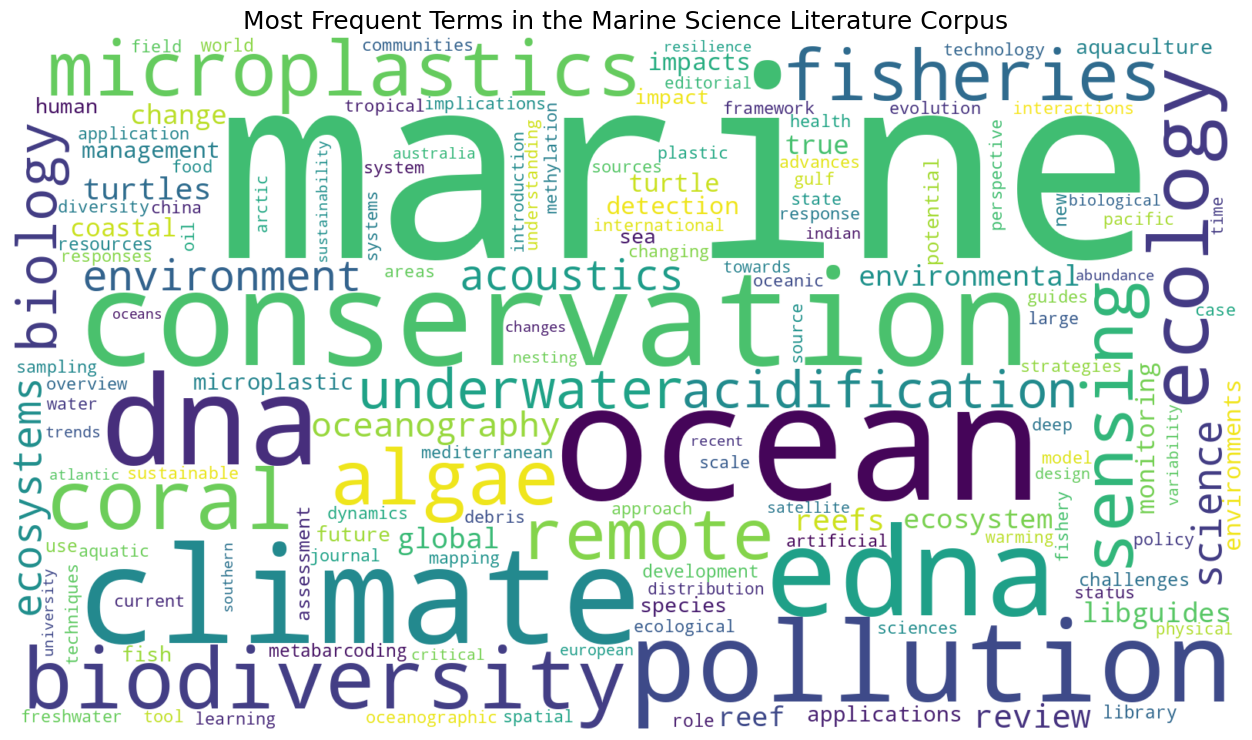

In [38]:
# ============================================================
# STEP 15 — WORD CLOUD
# ============================================================

# from wordcloud import WordCloud

word_frequency_dict = dict(
    zip(
        word_frequencies["word"],
        word_frequencies["frequency"]
    )
)

wordcloud = WordCloud(
    width=1600,
    height=900,
    background_color="white",
    max_words=150,
    collocations=False
).generate_from_frequencies(
    word_frequency_dict
)

plt.figure(figsize=(16, 9))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Most Frequent Terms in the Marine Science Literature Corpus",
    fontsize=18
)

plt.show()

How to use the word cloud The word cloud answers: Which terms occur most frequently across the corpus?

It does not answer: What are the major research themes?

That distinction is important academically. Your topic modelling provides the latter.

12. STEP 11 — LDA topic modelling: 5–15 topics

Now we can proceed with the actual modelling.

In [39]:
# ============================================================
# STEP 16 — LDA MODELLING
# ============================================================

# from gensim.models import LdaModel
# from gensim.models.coherencemodel import CoherenceModel

topic_range = range(5, 16)

lda_models = {}
lda_evaluation = []

for num_topics in topic_range:

    print(
        f"Training LDA with {num_topics} topics..."
    )

    model = LdaModel(
        corpus=bow_corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=42,
        passes=20,
        iterations=500,
        alpha="auto",
        eta="auto"
    )

    lda_models[num_topics] = model

    # Coherence
    coherence_model = CoherenceModel(
        model=model,
        texts=tokenized_documents.tolist(),
        dictionary=dictionary,
        coherence="c_v"
    )

    coherence = (
        coherence_model
        .get_coherence()
    )

    # Perplexity
    perplexity = np.exp(
        -model.log_perplexity(
            bow_corpus
        )
    )

    # Topic diversity
    top_words = []

    for topic_id in range(num_topics):

        words = [
            word
            for word, probability
            in model.show_topic(
                topic_id,
                topn=10
            )
        ]

        top_words.extend(words)

    diversity = (
        len(set(top_words))
        /
        len(top_words)
    )

    lda_evaluation.append({
        "num_topics": num_topics,
        "coherence_cv": coherence,
        "perplexity": perplexity,
        "topic_diversity": diversity
    })


lda_evaluation = pd.DataFrame(
    lda_evaluation
)

display(lda_evaluation)

Training LDA with 5 topics...
Training LDA with 6 topics...
Training LDA with 7 topics...
Training LDA with 8 topics...
Training LDA with 9 topics...
Training LDA with 10 topics...
Training LDA with 11 topics...
Training LDA with 12 topics...
Training LDA with 13 topics...
Training LDA with 14 topics...
Training LDA with 15 topics...


,num_topics,coherence_cv,perplexity,topic_diversity
0,5,0.356831,474.179813,0.860000
1,6,0.405939,471.872673,0.783333
2,7,0.415002,481.025991,0.814286
3,8,0.409349,487.360109,0.775000
4,9,0.409951,490.156308,0.811111
5,10,0.457929,500.262397,0.880000
6,11,0.474129,502.254443,0.800000
7,12,0.472704,510.946319,0.816667
8,13,0.506814,511.178460,0.823077
9,14,0.498848,522.252965,0.828571


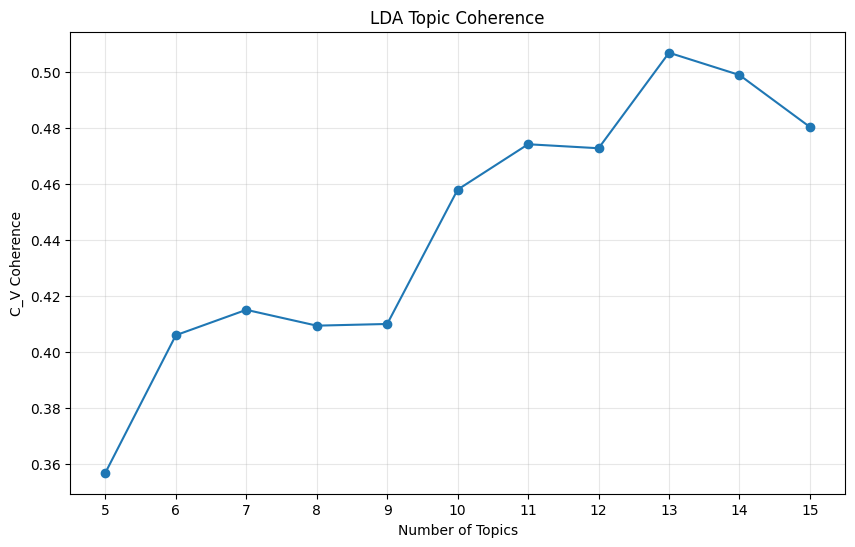

In [40]:
# ============================================================
# STEP 17 — LDA EVALUATION PLOTS
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    lda_evaluation["num_topics"],
    lda_evaluation["coherence_cv"],
    marker="o"
)

plt.xlabel("Number of Topics")
plt.ylabel("C_V Coherence")
plt.title("LDA Topic Coherence")

plt.xticks(
    lda_evaluation["num_topics"]
)

plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
#########################
#  perplexity
##########################



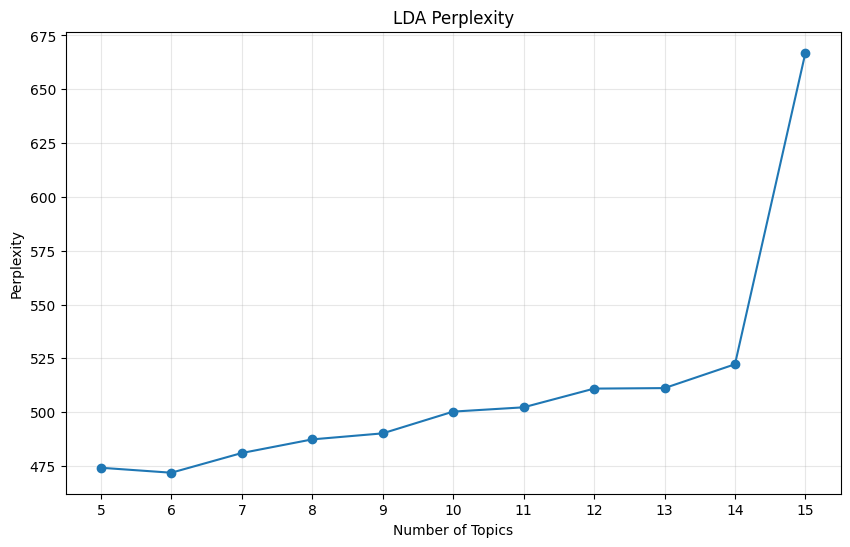

In [41]:
plt.figure(figsize=(10, 6))

plt.plot(
    lda_evaluation["num_topics"],
    lda_evaluation["perplexity"],
    marker="o"
)

plt.xlabel("Number of Topics")
plt.ylabel("Perplexity")
plt.title("LDA Perplexity")

plt.xticks(
    lda_evaluation["num_topics"]
)

plt.grid(True, alpha=0.3)

plt.show()

In [42]:
# ============================================================
# STEP 18 — TOPIC BALANCE METRICS
# This is one of the improvements I strongly recommend over simply choosing the highest coherence.
# ============================================================

def calculate_topic_balance(
    model,
    bow_corpus,
    num_topics
):

    topic_matrix = []

    for bow in bow_corpus:

        distribution = dict(
            model.get_document_topics(
                bow,
                minimum_probability=0
            )
        )

        topic_matrix.append([
            distribution.get(i, 0)
            for i in range(num_topics)
        ])

    topic_matrix = np.array(
        topic_matrix
    )

    mean_topic_share = (
        topic_matrix.mean(axis=0)
    )

    return {
        "min_topic_share":
            mean_topic_share.min(),

        "max_topic_share":
            mean_topic_share.max(),

        "topic_share_sd":
            mean_topic_share.std(),

        "topic_entropy":
            -np.sum(
                mean_topic_share
                *
                np.log(
                    mean_topic_share + 1e-12
                )
            )
    }


balance_results = []

for num_topics, model in lda_models.items():

    metrics = calculate_topic_balance(
        model,
        bow_corpus,
        num_topics
    )

    metrics["num_topics"] = num_topics

    balance_results.append(metrics)


balance_df = pd.DataFrame(
    balance_results
)

lda_evaluation = lda_evaluation.merge(
    balance_df,
    on="num_topics"
)

display(lda_evaluation)

,num_topics,coherence_cv,perplexity,topic_diversity,min_topic_share,max_topic_share,topic_share_sd,topic_entropy
0,5,0.356831,474.179813,0.860000,0.135510,0.257306,0.046168,1.582486
1,6,0.405939,471.872673,0.783333,0.091746,0.213744,0.038821,1.762075
2,7,0.415002,481.025991,0.814286,0.078119,0.189667,0.032688,1.917581
3,8,0.409349,487.360109,0.775000,0.079521,0.186448,0.030533,2.050322
4,9,0.409951,490.156308,0.811111,0.064095,0.140777,0.028940,2.160979
5,10,0.457929,500.262397,0.880000,0.061679,0.137420,0.028907,2.259547
6,11,0.474129,502.254443,0.800000,0.060480,0.115019,0.018463,2.376253
7,12,0.472704,510.946319,0.816667,0.043615,0.129075,0.023185,2.445797
8,13,0.506814,511.178460,0.823077,0.039804,0.116310,0.024079,2.514683
9,14,0.498848,522.252965,0.828571,0.034263,0.120297,0.026549,2.572618


In [43]:
# ============================================================
# STEP 19 — DISPLAY TOPIC WORDS
 # Do not automatically select the model from the metrics. Inspect the actual topics.
# ============================================================

def display_topics(
    model,
    n_words=15
):

    for topic_id in range(
        model.num_topics
    ):

        words = [
            word
            for word, probability
            in model.show_topic(
                topic_id,
                topn=n_words
            )
        ]

        print(
            f"Topic {topic_id + 1}:"
        )

        print(
            ", ".join(words)
        )

        print()


# Example
display_topics(
    lda_models[15],
    n_words=15
)

Topic 1:
marine, biodiversity, true, oil, overview, learning, applications, ecology, techniques, response, underwater, machine, evolution, approach, mapping

Topic 2:
environmental, management, species, global, fisheries, strategies, microplastics, transport, review, status, sustainability, invasive, marine, influence, classification

Topic 3:
dna, environment, microplastics, environments, fish, environmental, methylation, human, aquatic, detection, interactions, review, critical, abundance, water

Topic 4:
marine, remote, sensing, pollution, detection, monitoring, coastal, plastic, review, spatial, satellite, artificial, images, optical, challenges

Topic 5:
edna, underwater, science, metabarcoding, technology, marine, monitoring, application, freshwater, true, challenges, sampling, assessment, debris, tool

Topic 6:
marine, ecology, underwater, acoustics, university, biodiversity, sciences, extraction, deep, microplastics, litter, india, validation, performance, lake

Topic 7:
fisher

Start by examining 7 and 8 topics, because your previous analysis suggested those were strong candidates.
But after the corrected preprocessing, the best solution could change.

STEP 15 — Representative-paper validation

This is one of the most important steps in your project.

In [44]:
# ============================================================
# STEP 20 — REPRESENTATIVE PAPERS
# ============================================================

def get_representative_documents(
    model,
    bow_corpus,
    corpus_df,
    n=5
):

    results = []

    for doc_index, bow in enumerate(
        bow_corpus
    ):

        topic_distribution = dict(
            model.get_document_topics(
                bow,
                minimum_probability=0
            )
        )

        for topic_id, probability in (
            topic_distribution.items()
        ):

            results.append({
                "doc_index": doc_index,
                "topic": topic_id + 1,
                "probability": probability
            })

    results_df = pd.DataFrame(
        results
    )

    representative = (
        results_df
        .sort_values(
            ["topic", "probability"],
            ascending=[True, False]
        )
        .groupby("topic")
        .head(n)
        .copy()
    )

    paper_columns = [
        "paper_id",
        "title",
        "author_names",
        "publication_year",
        "journal",
        "doi_url",
        "paper_url"
    ]

    available_columns = [
        c
        for c in paper_columns
        if c in corpus_df.columns
    ]

    representative = representative.merge(
        corpus_df[available_columns],
        left_on="doc_index",
        right_index=True,
        how="left"
    )

    return representative

In [45]:
representative_8 = (
    get_representative_documents(
        lda_models[8],
        bow_corpus,
        analysis_corpus,
        n=5
    )
)

display(
    representative_8
)

,doc_index,topic,probability,paper_id,title,author_names,publication_year,journal,doi_url,paper_url
5440,680,1,0.915297,https://openalex.org/W2588132420,The status of marine biodiversity in the Easte...,Beth Polidoro; Gina M. Ralph; Kyle Strongin; M...,2017,Aquatic Conservation Marine and Freshwater Eco...,https://doi.org/10.1002/aqc.2744,https://doi.org/10.1002/aqc.2744
15072,1884,1,0.915291,https://openalex.org/W3093123576,Long-term insights into marine turtle sighting...,Zara L.R. Botterell; Rod Penrose; Matthew J. W...,2020,Journal of the Marine Biological Association o...,https://doi.org/10.1017/s0025315420000843,https://doi.org/10.1017/s0025315420000843
14768,1846,1,0.915259,https://openalex.org/W2802326380,"Phylogeny, biogeography and methodology: a met...",Joseph B. Pfaller; Milani Y. Chaloupka; Alan B...,2018,Scientific Reports,https://doi.org/10.1038/s41598-018-24262-w,https://doi.org/10.1038/s41598-018-24262-w
608,76,1,0.905783,https://openalex.org/W4387140887,Machine learning in marine ecology: an overvie...,Peter Rubbens; Stephanie J. Brodie; Tristan Co...,2023,ICES Journal of Marine Science,https://doi.org/10.1093/icesjms/fsad100,https://doi.org/10.1093/icesjms/fsad100
24408,3051,1,0.905777,https://openalex.org/W3112203788,UNT Dallas Library: BIOL 4290 Marine Ecology :...,Robert Taylor,2020,NaN,NaN,NaN
15681,1960,2,0.919637,https://openalex.org/W3023386372,Are we underestimating microplastic abundance ...,Penelope K. Lindeque; Matthew Cole; Rachel Cop...,2020,Environmental Pollution,https://doi.org/10.1016/j.envpol.2020.114721,https://doi.org/10.1016/j.envpol.2020.114721
22353,2794,2,0.910645,https://openalex.org/W4382632526,AirDNA sampler: An efficient and simple device...,Piyanun Harnpicharnchai; Panyapon Pumkaeo; Pao...,2023,PLoS ONE,https://doi.org/10.1371/journal.pone.0287567,https://doi.org/10.1371/journal.pone.0287567
23721,2965,2,0.899431,https://openalex.org/W2310539329,How nonspecifically DNA-binding proteins searc...,Yiding Ma; Yuhao Chen; Wancheng Yu; Kaifu Luo,2016,The Journal of Chemical Physics,https://doi.org/10.1063/1.4944905,https://doi.org/10.1063/1.4944905
22657,2832,2,0.899416,https://openalex.org/W3111362032,The Role of DNA in the Extracellular Environme...,Francesco Monticolo; Emanuela Palomba; Pasqual...,2020,Frontiers in Plant Science,https://doi.org/10.3389/fpls.2020.589837,https://doi.org/10.3389/fpls.2020.589837
22673,2834,2,0.899377,https://openalex.org/W2171107534,Persistence of mitochondrial DNA markers as fe...,Xiwei He; Huimei Chen; Wei Feng Shi; Yibin Cui...,2015,The Science of The Total Environment,https://doi.org/10.1016/j.scitotenv.2015.06.119,https://doi.org/10.1016/j.scitotenv.2015.06.119


In [46]:
# ============================================================
# STEP 21 — TOPIC VALIDATION TABLE
# ============================================================

def create_topic_validation_table(
    model,
    representative_df,
    n_words=12
):

    rows = []

    for topic in range(
        1,
        model.num_topics + 1
    ):

        words = [
            word
            for word, probability
            in model.show_topic(
                topic - 1,
                topn=n_words
            )
        ]

        papers = representative_df[
            representative_df["topic"] == topic
        ]

        paper_titles = (
            papers["title"]
            .dropna()
            .tolist()
        )

        rows.append({
            "topic": topic,
            "top_words": ", ".join(words),
            "representative_papers":
                " | ".join(paper_titles)
        })

    return pd.DataFrame(rows)


topic_validation = (
    create_topic_validation_table(
        lda_models[8],
        representative_8
    )
)

display(topic_validation)

,topic,top_words,representative_papers
0,1,"marine, biodiversity, true, turtle, overview, ...",The status of marine biodiversity in the Easte...
1,2,"dna, marine, biology, environment, libguides, ...",Are we underestimating microplastic abundance ...
2,3,"microplastics, marine, dna, human, ecosystem, ...",Potential risks of microplastics combined with...
3,4,"marine, remote, sensing, pollution, fisheries,...",Developing a functional definition of small-sc...
4,5,"marine, edna, conservation, science, turtles, ...",Exploring drivers and deterrents of the illega...
5,6,"underwater, acoustics, coral, ecology, marine,...",The unprecedented loss of Florida's reef‐build...
6,7,"ocean, climate, acidification, change, impacts...",Phytoplankton Responses to Ocean Climate Chang...
7,8,"algae, oceanography, review, applications, sea...",Introduction to Oceanographic and Biological A...



This is where you make the academic judgement.
For each topic ask:
1. Are the top words semantically coherent?
2. Do representative papers actually belong together?
3. Does the topic represent a meaningful marine-science theme?
4. Is the topic dominated by generic methodology words?
5. Is it just an artefact of PDF extraction?
6. Is it too broad?
7. Is it essentially a duplicate of another topic?



In [47]:
FINAL_LDA_TOPICS = 15

final_lda = lda_models[
    FINAL_LDA_TOPICS
]

print(
    "Final LDA model:",
    FINAL_LDA_TOPICS,
    "topics"
)

display_topics(
    final_lda,
    n_words=15
)

Final LDA model: 15 topics
Topic 1:
marine, biodiversity, true, oil, overview, learning, applications, ecology, techniques, response, underwater, machine, evolution, approach, mapping

Topic 2:
environmental, management, species, global, fisheries, strategies, microplastics, transport, review, status, sustainability, invasive, marine, influence, classification

Topic 3:
dna, environment, microplastics, environments, fish, environmental, methylation, human, aquatic, detection, interactions, review, critical, abundance, water

Topic 4:
marine, remote, sensing, pollution, detection, monitoring, coastal, plastic, review, spatial, satellite, artificial, images, optical, challenges

Topic 5:
edna, underwater, science, metabarcoding, technology, marine, monitoring, application, freshwater, true, challenges, sampling, assessment, debris, tool

Topic 6:
marine, ecology, underwater, acoustics, university, biodiversity, sciences, extraction, deep, microplastics, litter, india, validation, perform

If 7 becomes clearly superior after preprocessing, simply change:

FINAL_LDA_TOPICS = 7

STEP 18 — Document-topic assignments
Now assign each paper to its dominant topic.

In [48]:
# ============================================================
# STEP 22 — DOCUMENT-TOPIC ASSIGNMENTS
# ============================================================

document_topic_rows = []

for doc_index, bow in enumerate(
    bow_corpus
):

    distribution = dict(
        final_lda.get_document_topics(
            bow,
            minimum_probability=0
        )
    )

    dominant_topic = max(
        distribution,
        key=distribution.get
    )

    dominant_probability = (
        distribution[dominant_topic]
    )

    document_topic_rows.append({
        "doc_index": doc_index,
        "dominant_topic":
            dominant_topic + 1,
        "topic_probability":
            dominant_probability
    })


document_topics = pd.DataFrame(
    document_topic_rows
)

analysis_corpus = analysis_corpus.copy()

analysis_corpus = analysis_corpus.merge(
    document_topics,
    left_index=True,
    right_on="doc_index",
    how="left"
)

display(
    analysis_corpus[
        [
            "title",
            "dominant_topic",
            "topic_probability"
        ]
    ].head()
)

,title,dominant_topic,topic_probability
0,Practical Handbook of Marine Science,12,0.497794
1,Unoccupied Aircraft Systems in Marine Science ...,12,0.450096
2,Frontiers in Marine Science,8,0.451779
3,Machine intelligence and the data-driven futur...,10,0.315861
4,Big Data in Marine Science,4,0.491074


In [49]:
# ============================================================
# STEP 23 — TOPIC PREVALENCE
# ============================================================

topic_prevalence = (
    analysis_corpus[
        "dominant_topic"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("topic")
    .reset_index(name="document_count")
)

topic_prevalence["percentage"] = (
    topic_prevalence["document_count"]
    /
    len(analysis_corpus)
    *
    100
).round(1)

display(topic_prevalence)

,topic,document_count,percentage
0,1,146,4.3
1,2,105,3.1
2,3,360,10.7
3,4,381,11.3
4,5,197,5.8
5,6,178,5.3
6,7,60,1.8
7,8,115,3.4
8,9,406,12.0
9,10,99,2.9


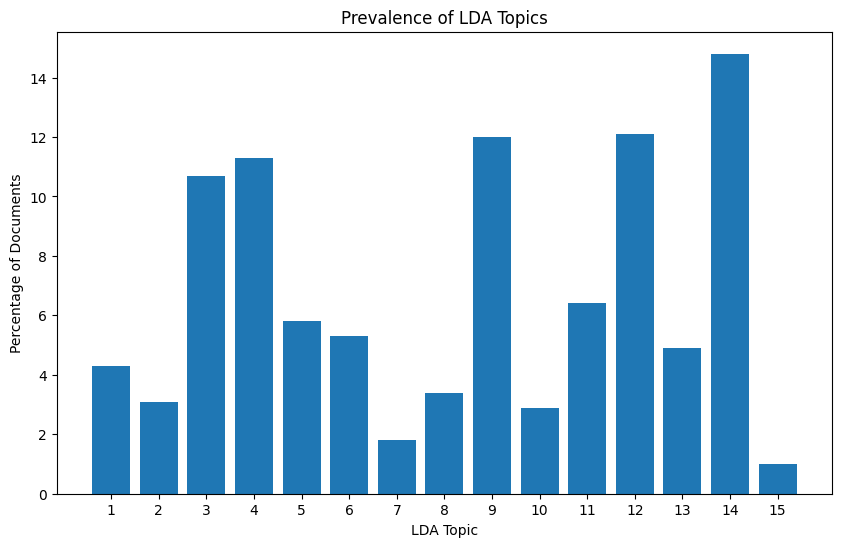

In [50]:
plt.figure(figsize=(10, 6))

plt.bar(
    topic_prevalence["topic"].astype(str),
    topic_prevalence["percentage"]
)

plt.xlabel("LDA Topic")
plt.ylabel("Percentage of Documents")
plt.title("Prevalence of LDA Topics")

plt.show()

STEP 20 — Topic trends over time
This will be particularly useful for your literature review.

In [51]:
# ============================================================
# STEP 24 — TOPIC TRENDS OVER TIME
# ============================================================

topic_year = (
    analysis_corpus
    .dropna(subset=["publication_year"])
    .groupby(
        [
            "publication_year",
            "dominant_topic"
        ]
    )
    .size()
    .reset_index(
        name="document_count"
    )
)

display(
    topic_year.head()
)

,publication_year,dominant_topic,document_count
0,2015,1,11
1,2015,2,11
2,2015,3,41
3,2015,4,23
4,2015,5,28


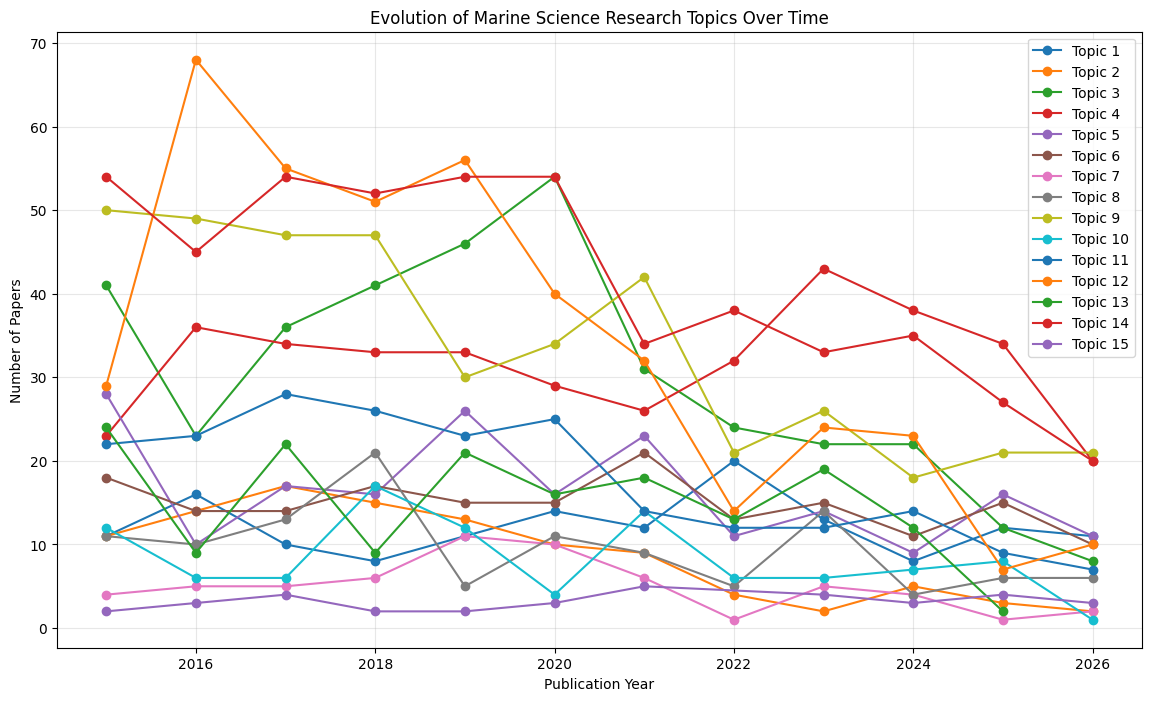

In [52]:
plt.figure(figsize=(14, 8))

for topic in sorted(
    topic_year["dominant_topic"].unique()
):

    subset = topic_year[
        topic_year["dominant_topic"] == topic
    ]

    plt.plot(
        subset["publication_year"],
        subset["document_count"],
        marker="o",
        label=f"Topic {int(topic)}"
    )

plt.xlabel("Publication Year")
plt.ylabel("Number of Papers")
plt.title(
    "Evolution of Marine Science Research Topics Over Time"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.show()

**BERTOPIC**

In [49]:
!pip install -q bertopic sentence-transformers umap-learn hdbscan

In [50]:
!pip install huggingface_hub

In [51]:
from huggingface_hub import notebook_login

notebook_login()

In [53]:
# ============================================================
# STEP 25 — BERTOPIC
# ============================================================

from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print(
    "Embedding model loaded successfully."
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded successfully.


In [54]:
bertopic_documents = (
    analysis_corpus[
        "topic_text_clean"
    ]
    .fillna("")
    .tolist()
)

In [55]:
topic_model = BERTopic(
    embedding_model=embedding_model,
    min_topic_size=5,
    calculate_probabilities=True,
    verbose=True
)

topics, probabilities = (
    topic_model.fit_transform(
        bertopic_documents
    )
)

2026-10-18 04:50:45,231 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/106 [00:00<?, ?it/s]

2026-10-18 04:51:11,673 - BERTopic - Embedding - Completed ✓
2026-10-18 04:51:11,677 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-18 04:51:48,439 - BERTopic - Dimensionality - Completed ✓
2026-10-18 04:51:48,441 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-18 04:51:49,462 - BERTopic - Cluster - Completed ✓
2026-10-18 04:51:49,468 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-18 04:51:49,571 - BERTopic - Representation - Completed ✓


STEP 22 — Inspect BERTopic

In [76]:
# ============================================================
# STEP 26 — BERTOPIC RESULTS
# ============================================================

topic_info = topic_model.get_topic_info()

display(topic_info)

,Topic,Count,Name,Representation,Representative_Docs
0,-1,529,-1_conservation_ecology_marine_biodiversity,"[conservation, ecology, marine, biodiversity, ...",[china role antarctic marine conservation fals...
1,0,190,0_turtles_turtle_nesting_marine,"[turtles, turtle, nesting, marine, species, fo...",[impact plastic pollution marine turtles false...
2,1,165,1_acoustics_underwater_sound_measurement,"[acoustics, underwater, sound, measurement, co...","[overview underwater acoustics false, underwat..."
3,2,161,2_algae_cyanobacteria_source_potential,"[algae, cyanobacteria, source, potential, revi...","[algae false, algae false, algae false]"
4,3,154,3_acidification_ocean_responses_impacts,"[acidification, ocean, responses, impacts, bou...","[ocean acidification false, ocean acidificatio..."
...,...,...,...,...,...
86,85,7,85_green_walls_buildings_adaptability,"[green, walls, buildings, adaptability, design...",[adaptation mitigation climate change envelope...
87,86,6,86_fishes_epicenter_mesophotic_spot,"[fishes, epicenter, mesophotic, spot, hidden, ...",[hidden biodiversity tropical coral reefs fals...
88,87,5,87_protist_timing_meiofauna_periodicity,"[protist, timing, meiofauna, periodicity, phan...",[characteristics meiofauna extreme marine ecos...
89,88,5,88_shipping_dematel_relating_operations,"[shipping, dematel, relating, operations, coat...","[marine pollution shipping activities false, g..."


The -1 topic represents documents that BERTopic considers outliers. Don't automatically delete them.

STEP 23 — BERTopic visualisation

In [77]:
# Topic bar chart

topic_model.visualize_barchart(
    top_n_topics=15
)

In [78]:
# Topic hierarchy

topic_model.visualize_hierarchy()

In [59]:
# Visualize the topics
!pip install -q pyLDAvis matplotlib seaborn

In [60]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

from IPython.display import display

# Folder for saved visualisations
OUTPUT_DIR = "marine_topic_visualisations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

!pip install --upgrade jupyter_client

import warnings

warnings.filterwarnings(
    "ignore",
    message=r".*datetime\.datetime\.utcnow\(\) is deprecated.*",
    category=DeprecationWarning
)

Interactive topic visualisation with pyLDAvis This uses the Gensim integration recommended for visualising an already-trained LDA model.

In [79]:
# Use your selected, trained LDA model.
# If your model has another variable name, replace final_lda below.

lda_vis = gensimvis.prepare(
    final_lda,
    bow_corpus,
    dictionary,
    sort_topics=False
)

# Display the interactive visualisation in the notebook
display(pyLDAvis.display(lda_vis))

# Save a standalone HTML copy
html_path = os.path.join(OUTPUT_DIR, "marine_lda_interactive.html")
pyLDAvis.save_html(lda_vis, html_path)

print("Saved interactive visualisation to:", html_path)

Saved interactive visualisation to: /content/marine_literature/data/final_analysis/marine_lda_interactive.html


**NEED TO UNDERSTAND THE NUBERS IN FRONT OF THE TOPICS**

In [63]:
# ============================================================
# STEP 27 — BERTOPIC REPRESENTATIVE DOCUMENTS
# ============================================================

for topic_id in topic_info[
    "Topic"
].tolist():

    if topic_id == -1:
        continue

    print("\n" + "=" * 100)

    print(
        f"BERTopic {topic_id}"
    )

    print("=" * 100)

    print(
        topic_model.get_topic(
            topic_id
        )
    )

    print("\nRepresentative documents:")

    docs = topic_model.get_representative_docs(
        topic_id
    )

    for doc in docs[:5]:
        print(
            "-",
            doc[:250]
        )


BERTopic 0
[('turtles', np.float64(0.08130521589820909)), ('turtle', np.float64(0.06364061074075168)), ('nesting', np.float64(0.024788604417848338)), ('marine', np.float64(0.016622701952395465)), ('species', np.float64(0.015331507671389402)), ('foraging', np.float64(0.014118799486280436)), ('islands', np.float64(0.012265881141810443)), ('gulf', np.float64(0.011972113197287953)), ('mediterranean', np.float64(0.011590946925684412)), ('coast', np.float64(0.01125836154269483))]

Representative documents:
- impact plastic pollution marine turtles false
- advances biology conservation marine turtles false
- marine turtles false

BERTopic 1
[('acoustics', np.float64(0.12477143493861804)), ('underwater', np.float64(0.12240971106242775)), ('sound', np.float64(0.029368807697906733)), ('measurement', np.float64(0.020149515929267604)), ('contributions', np.float64(0.018817949864310676)), ('experiments', np.float64(0.018262716986699557)), ('applied', np.float64(0.017306876138474567)), ('metamateri

In [64]:
# ============================================================
# STEP 28 — ADD BERTOPIC ASSIGNMENTS
# ============================================================

analysis_corpus[
    "bertopic_topic"
] = topics

analysis_corpus[
    "bertopic_probability"
] = [
    max(probability)
    if probability is not None
    and len(probability) > 0
    else np.nan
    for probability in probabilities
]

display(
    analysis_corpus[
        [
            "title",
            "dominant_topic",
            "topic_probability",
            "bertopic_topic"
        ]
    ].head(20)
)

,title,dominant_topic,topic_probability,bertopic_topic
0,Practical Handbook of Marine Science,12,0.497794,20
1,Unoccupied Aircraft Systems in Marine Science ...,12,0.450096,-1
2,Frontiers in Marine Science,8,0.451779,20
3,Machine intelligence and the data-driven futur...,10,0.315861,72
4,Big Data in Marine Science,4,0.491074,20
5,Indian Journal of Geo-Marine Sciences,11,0.434240,49
6,Annals of Marine Science,12,0.753274,49
7,Annual Review of Marine Science,8,0.358718,20
8,Setting the stage for the machine intelligence...,4,0.217315,72
9,World Journal of Fish and Marine Sciences,11,0.454261,6


STEP 26 — Compare LDA and BERTopic
This is where your study becomes much stronger.

In [65]:
# ============================================================
# STEP 29 — LDA vs BERTOPIC
# ============================================================

comparison = pd.crosstab(
    analysis_corpus["dominant_topic"],
    analysis_corpus["bertopic_topic"]
)

display(comparison)

bertopic_topic,-1,0,1,2,3,4,5,6,7,8,...,80,81,82,83,84,85,86,87,88,89
dominant_topic,,,,,,,,,,,,,,,,,,,,,
1,29,3,12,3,1,1,1,0,4,0,...,3,0,0,0,0,0,0,3,1,2
2,18,9,2,2,0,0,1,20,3,0,...,0,0,0,0,3,1,0,0,0,0
3,28,3,5,14,1,5,129,4,1,0,...,0,0,0,0,3,0,0,0,0,0
4,75,15,2,1,1,0,1,4,7,1,...,0,0,7,0,0,0,0,0,3,1
5,30,1,45,2,0,0,4,2,3,0,...,0,0,0,0,0,0,0,0,0,0
6,35,3,34,2,0,1,1,2,4,1,...,2,0,0,0,1,1,1,0,0,0
7,3,0,10,0,3,0,0,12,4,0,...,0,1,0,0,0,1,0,1,0,0
8,7,2,3,0,0,6,0,4,46,0,...,0,0,0,3,0,0,0,0,0,1
9,22,1,2,3,144,131,2,6,4,0,...,0,0,0,1,0,4,0,0,0,0


This shows which LDA topics correspond to BERTopic topics.:

STEP 27 — Quantitative model comparison
You can calculate agreement using ARI and NMI.

In [66]:
# ============================================================
# STEP 30 — MODEL AGREEMENT
# ============================================================

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

valid = (
    analysis_corpus[
        "bertopic_topic"
    ] != -1
)

lda_labels = (
    analysis_corpus
    .loc[valid, "dominant_topic"]
)

bertopic_labels = (
    analysis_corpus
    .loc[valid, "bertopic_topic"]
)

ari = adjusted_rand_score(
    lda_labels,
    bertopic_labels
)

nmi = normalized_mutual_info_score(
    lda_labels,
    bertopic_labels
)

print(
    f"Adjusted Rand Index: {ari:.3f}"
)

print(
    f"Normalized Mutual Information: {nmi:.3f}"
)

Adjusted Rand Index: 0.214
Normalized Mutual Information: 0.433


In [67]:

# ============================================================
# STEP 31: NAMED ENTITY RECOGNITION (NER) AND
#          RELATION EXTRACTION (RE)
# ============================================================

import pandas as pd
import re
import spacy
from IPython.display import display

# ------------------------------------------------------------
# 31.1 Use the existing analysis corpus
# ------------------------------------------------------------
if "analysis_corpus" in globals():
    ner_re_corpus = analysis_corpus.copy()
elif "df" in globals():
    ner_re_corpus = df.copy()
else:
    raise NameError(
        "Neither 'analysis_corpus' nor 'df' exists. "
        "Run your corpus-loading step first."
    )

# Select the best available document identifier.
id_candidates = ["paper_id", "openalex_id", "id", "doi"]
id_col = next(
    (col for col in id_candidates if col in ner_re_corpus.columns),
    None
)

if id_col:
    ner_re_corpus["document_id"] = (
        ner_re_corpus[id_col].fillna("").astype(str)
    )
else:
    ner_re_corpus["document_id"] = (
        ner_re_corpus.index.astype(str)
    )

# Build text from fields that actually exist in the corpus.
candidate_text_columns = [
    "title", "abstract", "keywords", "introduction",
    "methods", "results", "discussion",
    "topic_text_clean", "full_text", "content"
]

available_text_columns = [
    col for col in candidate_text_columns
    if col in ner_re_corpus.columns
]

if not available_text_columns:
    raise ValueError(
        "No text columns found. Available columns: "
        + str(ner_re_corpus.columns.tolist())
    )


def safe_text(value):
    if pd.isna(value):
        return ""
    value = str(value).strip()
    return "" if value.lower() in {"nan", "none", "null"} else value


def combine_text(row, max_chars=20000):
    parts = []
    for col in available_text_columns:
        value = safe_text(row[col])
        if value:
            parts.append(value)
    return " ".join(parts)[:max_chars]


ner_re_corpus["ner_re_text"] = ner_re_corpus.apply(
    combine_text, axis=1
)

if "title" in ner_re_corpus.columns:
    ner_re_corpus["source_title"] = (
        ner_re_corpus["title"].fillna("").astype(str)
    )
else:
    ner_re_corpus["source_title"] = ""


# ------------------------------------------------------------
# 31.2 Load spaCy
# Run once in a separate cell if not installed:
# !pip -q install spacy
# !python -m spacy download en_core_web_sm
# ------------------------------------------------------------
try:
    nlp
except NameError:
    nlp = spacy.load("en_core_web_sm")


# ------------------------------------------------------------
# 31.3 Add a starter marine-science entity dictionary
# ------------------------------------------------------------
marine_entity_terms = {
    "ECOSYSTEM": [
        "Great Barrier Reef", "coral reef", "seagrass meadow",
        "mangrove forest", "marine ecosystem", "deep sea",
        "estuary", "intertidal zone"
    ],
    "MARINE_ORGANISM": [
        "green turtle", "loggerhead turtle", "marine turtle",
        "coral", "phytoplankton", "zooplankton", "reef fish",
        "marine mammal", "seagrass", "mangrove"
    ],
    "POLLUTANT": [
        "microplastic", "microplastics", "plastic pollution",
        "marine debris", "heavy metal", "oil pollution"
    ],
    "SCIENTIFIC_METHOD": [
        "environmental DNA", "eDNA", "DNA metabarcoding",
        "remote sensing", "acoustic telemetry",
        "underwater acoustics", "stable isotope analysis",
        "satellite imagery", "machine learning"
    ],
    "STATISTICAL_METHOD": [
        "linear regression", "logistic regression",
        "generalized linear model", "generalised linear model",
        "mixed effects model", "mixed-effects model",
        "principal component analysis", "random forest",
        "Bayesian model", "time series analysis",
        "topic modelling", "topic modeling"
    ],
    "LIFE_STAGE": [
        "larvae", "larval stage", "hatchling", "hatchlings",
        "juvenile", "juveniles", "adult", "adults",
        "spawning", "recruitment", "maturation",
        "reproduction", "embryonic development"
    ]
}

if "marine_entity_ruler" not in nlp.pipe_names:
    ruler = nlp.add_pipe(
        "entity_ruler",
        name="marine_entity_ruler",
        before="ner",
        config={"overwrite_ents": False}
    )
    ruler.add_patterns([
        {"label": label, "pattern": term}
        for label, terms in marine_entity_terms.items()
        for term in terms
    ])


# ------------------------------------------------------------
# 31.4 Define candidate relation triggers
# ------------------------------------------------------------
relation_triggers = {
    "increase": "INCREASES",
    "increases": "INCREASES",
    "increased": "INCREASES",
    "reduce": "REDUCES",
    "reduces": "REDUCES",
    "reduced": "REDUCES",
    "decrease": "REDUCES",
    "decreases": "REDUCES",
    "decreased": "REDUCES",
    "affect": "AFFECTS",
    "affects": "AFFECTS",
    "affected": "AFFECTS",
    "impact": "IMPACTS",
    "impacts": "IMPACTS",
    "impacted": "IMPACTS",
    "cause": "CAUSES",
    "causes": "CAUSES",
    "caused": "CAUSES",
    "influence": "INFLUENCES",
    "influences": "INFLUENCES",
    "influenced": "INFLUENCES",
    "predict": "PREDICTS",
    "predicts": "PREDICTS",
    "predicted": "PREDICTS",
    "contain": "CONTAINS",
    "contains": "CONTAINS",
    "feed": "FEEDS_ON",
    "feeds": "FEEDS_ON",
    "consume": "CONSUMES",
    "consumes": "CONSUMES",
    "inhabit": "INHABITS",
    "inhabits": "INHABITS",
    "migrate": "MIGRATES",
    "migrates": "MIGRATES",
    "reproduce": "REPRODUCES",
    "reproduces": "REPRODUCES"
}


def get_phrase(token, max_tokens=10):
    """Return a short phrase around a dependency token."""
    subtree = list(token.subtree)
    if not subtree:
        return token.text

    start = min(t.i for t in subtree)
    end = max(t.i for t in subtree) + 1
    span = token.doc[start:end]

    if len(span) > max_tokens:
        span = token.doc[
            max(token.i - 4, 0): min(token.i + 6, len(token.doc))
        ]

    return span.text.strip(" ,.;:")


def extract_candidate_relations(doc, document_id, title):
    output = []

    for sentence in doc.sents:
        for verb in sentence:
            if verb.pos_ not in {"VERB", "AUX"}:
                continue

            relation = relation_triggers.get(verb.text.lower())
            if relation is None:
                relation = relation_triggers.get(verb.lemma_.lower())
            if relation is None:
                continue

            subjects = [
                child for child in verb.children
                if child.dep_ in {"nsubj", "nsubjpass", "csubj"}
            ]

            objects = [
                child for child in verb.children
                if child.dep_ in {"dobj", "obj", "attr", "oprd", "dative"}
            ]

            # Include objects of prepositions, e.g. "associated with X".
            for prep in [
                child for child in verb.children
                if child.dep_ == "prep"
            ]:
                objects.extend([
                    child for child in prep.children
                    if child.dep_ in {"pobj", "obj"}
                ])

            # Deduplicate while preserving order.
            subjects = list({t.i: t for t in subjects}.values())
            objects = list({t.i: t for t in objects}.values())

            for subject in subjects:
                for obj in objects:
                    subject_text = get_phrase(subject)
                    object_text = get_phrase(obj)

                    if (
                        subject_text and object_text
                        and subject_text.lower() != object_text.lower()
                    ):
                        output.append({
                            "document_id": document_id,
                            "title": title,
                            "subject": subject_text,
                            "relation": relation,
                            "object": object_text,
                            "trigger": verb.text,
                            "evidence_sentence": sentence.text.strip(),
                            "extraction_method": "spaCy dependency rules"
                        })

    return output


# ------------------------------------------------------------
# 31.5 Run NER and RE across the corpus
# ------------------------------------------------------------
entity_rows = []
relation_rows = []

documents = list(zip(
    ner_re_corpus["document_id"].astype(str),
    ner_re_corpus["source_title"].astype(str),
    ner_re_corpus["ner_re_text"].fillna("").astype(str)
))

for (document_id, title, text_value), doc in zip(
    documents,
    nlp.pipe(
        [item[2] for item in documents],
        batch_size=16
    )
):
    if not text_value.strip():
        continue

    # Named entity mentions
    for ent in doc.ents:
        sentence_context = next(
            (
                sent.text.strip()
                for sent in doc.sents
                if sent.start <= ent.start and ent.end <= sent.end
            ),
            ""
        )

        entity_rows.append({
            "document_id": document_id,
            "title": title,
            "entity": ent.text,
            "entity_type": ent.label_,
            "sentence_context": sentence_context
        })

    # Candidate relations
    relation_rows.extend(
        extract_candidate_relations(doc, document_id, title)
    )


# ------------------------------------------------------------
# 31.6 Create output tables
# ------------------------------------------------------------
entities_df = pd.DataFrame(
    entity_rows,
    columns=[
        "document_id", "title", "entity",
        "entity_type", "sentence_context"
    ]
)

relations_df = pd.DataFrame(
    relation_rows,
    columns=[
        "document_id", "title", "subject", "relation",
        "object", "trigger", "evidence_sentence",
        "extraction_method"
    ]
)

# Table A: individual entity mentions
if not entities_df.empty:
    entity_frequency_table = (
        entities_df.groupby(["entity_type", "entity"])
        .agg(
            mention_count=("entity", "size"),
            document_count=("document_id", "nunique")
        )
        .reset_index()
        .sort_values(
            ["document_count", "mention_count"],
            ascending=False
        )
    )
else:
    entity_frequency_table = pd.DataFrame(
        columns=[
            "entity_type", "entity",
            "mention_count", "document_count"
        ]
    )

# Table B: relation counts
if not relations_df.empty:
    relation_summary_table = (
        relations_df.groupby("relation")
        .agg(
            triple_count=("relation", "size"),
            document_count=("document_id", "nunique"),
            unique_subjects=("subject", "nunique"),
            unique_objects=("object", "nunique")
        )
        .reset_index()
        .sort_values("triple_count", ascending=False)
    )
else:
    relation_summary_table = pd.DataFrame(
        columns=[
            "relation", "triple_count", "document_count",
            "unique_subjects", "unique_objects"
        ]
    )


# ------------------------------------------------------------
# 31.7 Display results as notebook tables
# ------------------------------------------------------------
print("TABLE 1 — NER: individual entity mentions")
display(entities_df.head(30))

print("TABLE 2 — NER: entity frequency and document coverage")
display(entity_frequency_table.head(30))

print("TABLE 3 — RE: candidate subject–relation–object triples")
display(relations_df.head(30))

print("TABLE 4 — RE: relation summary")
display(relation_summary_table)

print("NER entity mentions:", len(entities_df))
print("RE candidate triples:", len(relations_df))
print("Text fields used:", available_text_columns)


TABLE 1 — NER: individual entity mentions


,document_id,title,entity,entity_type,sentence_context
0,https://openalex.org/W2884132865,Unoccupied Aircraft Systems in Marine Science ...,Unoccupied Aircraft Systems,ORG,Unoccupied Aircraft Systems in Marine Science ...
1,https://openalex.org/W4366342697,Big Data in Marine Science,Big Data,ORG,Big Data in Marine Science
2,https://openalex.org/W4298303828,Indian Journal of Geo-Marine Sciences,Indian Journal of,ORG,Indian Journal of Geo-Marine Sciences False in...
3,https://openalex.org/W4298303828,Indian Journal of Geo-Marine Sciences,Geo-Marine Sciences,ORG,Indian Journal of Geo-Marine Sciences False in...
4,https://openalex.org/W4298303828,Indian Journal of Geo-Marine Sciences,indian,NORP,Indian Journal of Geo-Marine Sciences False in...
5,https://openalex.org/W4298303828,Indian Journal of Geo-Marine Sciences,geo marine,PRODUCT,Indian Journal of Geo-Marine Sciences False in...
6,https://openalex.org/W603264994,Annual Review of Marine Science,Annual Review of Marine Science False,ORG,Annual Review of Marine Science False annual r...
7,https://openalex.org/W3036672024,Setting the stage for the machine intelligence...,False,PRODUCT,Setting the stage for the machine intelligence...
8,https://openalex.org/W4403377110,World Journal of Fish and Marine Sciences,World Journal of Fish and Marine Sciences False,ORG,World Journal of Fish and Marine Sciences Fals...
9,https://openalex.org/W4231236862,Marine science and technology,False,PRODUCT,Marine science and technology False marine sci...


TABLE 2 — NER: entity frequency and document coverage


,entity_type,entity,mention_count,document_count
1797,PRODUCT,False,734,734
1827,SCIENTIFIC_METHOD,remote sensing,257,196
1824,SCIENTIFIC_METHOD,eDNA,226,189
1786,POLLUTANT,microplastics,304,188
1828,SCIENTIFIC_METHOD,underwater acoustics,250,168
525,MARINE_ORGANISM,coral,211,135
1608,PERSON,False,115,115
557,NORP,False,80,80
106,ECOSYSTEM,coral reef,128,79
1840,WORK_OF_ART,False,79,79


TABLE 3 — RE: candidate subject–relation–object triples


,document_id,title,subject,relation,object,trigger,evidence_sentence,extraction_method
0,https://openalex.org/W2940168746,Marine Science Affect Scale,Marine Science Affect Scale False marine science,AFFECTS,scale,affect,Marine Science Affect Scale False marine scien...,spaCy dependency rules
1,https://openalex.org/W3167589714,Technical methodologies for the assessment of ...,Technical methodologies for the assessment of the,IMPACTS,reclamation projects,impacts,Technical methodologies for the assessment of ...,spaCy dependency rules
2,https://openalex.org/W3167589714,Technical methodologies for the assessment of ...,Technical methodologies for the assessment of the,IMPACTS,marine ecology,impacts,Technical methodologies for the assessment of ...,spaCy dependency rules
3,https://openalex.org/W4389298533,Marine ecology: Increased fishing subsidy for ...,False marine ecology,INCREASES,fishing subsidy seabirds false,increased,Marine ecology: Increased fishing subsidy for ...,spaCy dependency rules
4,https://openalex.org/W7163014839,Impacts of jetty construction on hydrodynamics...,"ecology: a case study of Tongzhou Bay, Nantong",IMPACTS,seabed morphology marine ecology case tongzhou...,impacts,Impacts of jetty construction on hydrodynamics...,spaCy dependency rules
5,https://openalex.org/W2025328010,Predicting climate-driven regime shifts versus...,potential in coral reefs False predicting clim...,PREDICTS,climate driven regime shifts,predicting,Predicting climate-driven regime shifts versus...,spaCy dependency rules
6,https://openalex.org/W2578331757,Climate impacts on global hot spots of marine ...,Climate impacts on global hot spots of,IMPACTS,global hot spots marine biodiversity,impacts,Climate impacts on global hot spots of marine ...,spaCy dependency rules
7,https://openalex.org/W4307700104,Climate Disruption Caused by a Decline in Mari...,Climate Disruption Caused by a Decline in,CAUSES,decline marine biodiversity pollution,caused,Climate Disruption Caused by a Decline in Mari...,spaCy dependency rules
8,https://openalex.org/W1988521619,Force majeure: Will climate change affect our ...,Will climate change,AFFECTS,our ability to attain Good Environmental Statu...,affect,Force majeure: Will climate change affect our ...,spaCy dependency rules
9,https://openalex.org/W1988521619,Force majeure: Will climate change affect our ...,False force majeure climate change,AFFECTS,ability,affect,False force majeure climate change affect abil...,spaCy dependency rules


TABLE 4 — RE: relation summary


,relation,triple_count,document_count,unique_subjects,unique_objects
2,IMPACTS,20,14,17,16
0,AFFECTS,14,9,14,11
3,INCREASES,14,8,11,13
6,REDUCES,5,4,4,5
1,CAUSES,3,3,3,3
4,INFLUENCES,3,2,2,3
5,PREDICTS,3,2,3,3


NER entity mentions: 5574
RE candidate triples: 62
Text fields used: ['title', 'abstract', 'introduction', 'methods', 'results', 'discussion', 'topic_text_clean']


In [68]:

# Save NER and RE tables to a separate Excel workbook
output_file = (
    "/content/marine_literature/data/"
    "marine_science_NER_RE_tables.xlsx"
)

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    entities_df.to_excel(
        writer, sheet_name="NER Mentions", index=False
    )
    entity_frequency_table.to_excel(
        writer, sheet_name="NER Frequencies", index=False
    )
    relations_df.to_excel(
        writer, sheet_name="RE Triples", index=False
    )
    relation_summary_table.to_excel(
        writer, sheet_name="RE Summary", index=False
    )

print("Saved tables to:", output_file)


Saved tables to: /content/marine_literature/data/marine_science_NER_RE_tables.xlsx


In [69]:
# ============================================================
# STEP 32 — FINAL LITERATURE REVIEW TABLE
# ============================================================

review_columns = [
    "paper_id",
    "title",
    "author_names",
    "publication_year",
    "publication_date",
    "journal",
    "doi_url",
    "paper_url",
    "document_type",
    "research_objective",
    "hypothesis",
    "methods_detected",
    "statistical_methods",
    "results_summary",
    "dominant_topic",
    "topic_probability",
    "bertopic_topic"
]

review_columns = [
    col
    for col in review_columns
    if col in analysis_corpus.columns
]

literature_review_table = (
    analysis_corpus[
        review_columns
    ]
    .copy()
)

display(
    literature_review_table.head()
)

,paper_id,title,author_names,publication_year,publication_date,journal,doi_url,paper_url,document_type,dominant_topic,topic_probability,bertopic_topic
0,https://openalex.org/W1993512136,Practical Handbook of Marine Science,Michael J. Kennish,2019,2019-07-12,CRC Press eBooks,https://doi.org/10.1201/b22246,https://doi.org/10.1201/b22246,research_article,12,0.497794,20
1,https://openalex.org/W2884132865,Unoccupied Aircraft Systems in Marine Science ...,David W. Johnston,2018,2018-07-18,Annual Review of Marine Science,https://doi.org/10.1146/annurev-marine-010318-...,https://doi.org/10.1146/annurev-marine-010318-...,research_article,12,0.450096,-1
2,https://openalex.org/W4232999154,Frontiers in Marine Science,NaN,2017,2017-03-20,Frontiers in Marine Science,https://doi.org/10.3389/fmars,https://doi.org/10.3389/fmars,research_article,8,0.451779,20
3,https://openalex.org/W3016465642,Machine intelligence and the data-driven futur...,Ketil Malde; Nils Olav Handegard; Line Eikvil;...,2019,2019-03-12,ICES Journal of Marine Science,https://doi.org/10.1093/icesjms/fsz057,https://doi.org/10.1093/icesjms/fsz057,research_article,10,0.315861,72
4,https://openalex.org/W4366342697,Big Data in Marine Science,"Lionel Guidi; Fernàndez-Guerra, Antonio; Bakke...",2020,2020-04-29,Flanders Marine Institute (Flanders Marine Ins...,https://doi.org/10.5281/zenodo.3755792,https://doi.org/10.5281/zenodo.3755792,research_article,4,0.491074,20


In [70]:
# ============================================================
# STEP 33 — EXPORT RESULTS
# ============================================================

OUTPUT_DIR = os.path.join(
    DATA_DIR,
    "final_analysis"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Final corpus
analysis_corpus.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_marine_literature_corpus.csv"
    ),
    index=False
)

# Document type summary
document_type_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "document_type_summary.csv"
    ),
    index=False
)

# Vocabulary
word_frequencies.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "vocabulary_frequencies.csv"
    ),
    index=False
)

# LDA evaluation
lda_evaluation.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_model_evaluation.csv"
    ),
    index=False
)

# Topic prevalence
topic_prevalence.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_topic_prevalence.csv"
    ),
    index=False
)

# Topic validation
topic_validation.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_topic_validation.csv"
    ),
    index=False
)

# LDA/BERTopic comparison
comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_bertopic_comparison.csv"
    )
)

print(
    "Analysis outputs saved to:"
)

print(
    OUTPUT_DIR
)

Analysis outputs saved to:
/content/marine_literature/data/final_analysis


In [71]:
# ============================================================
# STEP 34 — SAVE WORD CLOUD
# ============================================================

wordcloud_path = os.path.join(
    OUTPUT_DIR,
    "marine_science_wordcloud.png"
)

wordcloud.to_file(
    wordcloud_path
)

print(
    "Saved:",
    wordcloud_path
)

Saved: /content/marine_literature/data/final_analysis/marine_science_wordcloud.png


In [72]:

import pandas as pd

[(name, obj.shape)
 for name, obj in globals().items()
 if isinstance(obj, pd.DataFrame)]

[('openalex_raw', (3800, 23)),
 ('with_doi', (3322, 23)),
 ('without_doi', (416, 23)),
 ('corpus', (3371, 40)),
 ('document_type_summary', (9, 3)),
 ('analysis_corpus', (3371, 51)),
 ('word_frequencies', (1260, 2)),
 ('lda_evaluation', (11, 8)),
 ('balance_df', (11, 5)),
 ('representative_8', (40, 10)),
 ('topic_validation', (8, 3)),
 ('document_topics', (3371, 3)),
 ('topic_prevalence', (15, 3)),
 ('topic_year', (178, 3)),
 ('subset', (11, 3)),
 ('topic_info', (91, 5)),
 ('comparison', (15, 91)),
 ('ner_re_corpus', (3371, 54)),
 ('entities_df', (5574, 5)),
 ('relations_df', (62, 8)),
 ('entity_frequency_table', (1875, 4)),
 ('relation_summary_table', (7, 5)),
 ('literature_review_table', (3371, 12))]

In [73]:

df = corpus

print("Number of papers:", len(df))
print("Columns:", df.columns.tolist())

Number of papers: 3371
Columns: ['openalex_id', 'doi', 'title', 'authors', 'author_count', 'publication_year', 'publication_date', 'journal', 'publisher', 'volume', 'issue', 'first_page', 'last_page', 'article_number', 'cited_by_count', 'is_oa', 'oa_status', 'oa_url', 'best_oa_url', 'pdf_url', 'search_term', 'doi_normalised', 'title_normalised', 'doi_url', 'paper_url', 'author_names', 'paper_id', 'review', 'methods', 'mapping', 'software', 'model', 'guidelines', 'book_chapter', 'statistics', 'document_type', 'marine_term_in_title', 'screening_decision', 'screening_reason', 'screening_notes']


In [74]:

from pathlib import Path
import pandas as pd

file_path = Path(
    "/content/marine_literature/data/"
    "marine_science_master_corpus.csv"
)

if file_path.exists():
    df = pd.read_csv(file_path)
    print("File:", file_path.name)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    display(df.head())
else:
    print("File not found at:", file_path)


File: marine_science_master_corpus.csv
Rows: 3371
Columns: ['openalex_id', 'doi', 'title', 'authors', 'author_count', 'publication_year', 'publication_date', 'journal', 'publisher', 'volume', 'issue', 'first_page', 'last_page', 'article_number', 'cited_by_count', 'is_oa', 'oa_status', 'oa_url', 'best_oa_url', 'pdf_url', 'search_term', 'doi_normalised', 'title_normalised', 'doi_url', 'paper_url', 'author_names', 'paper_id']


,openalex_id,doi,title,authors,author_count,publication_year,publication_date,journal,publisher,volume,...,oa_url,best_oa_url,pdf_url,search_term,doi_normalised,title_normalised,doi_url,paper_url,author_names,paper_id
0,https://openalex.org/W1993512136,https://doi.org/10.1201/b22246,Practical Handbook of Marine Science,['Michael J. Kennish'],1,2019,2019-07-12,CRC Press eBooks,CRC Press,NaN,...,NaN,NaN,NaN,marine science,10.1201/b22246,practical handbook of marine science,https://doi.org/10.1201/b22246,https://doi.org/10.1201/b22246,Michael J. Kennish,https://openalex.org/W1993512136
1,https://openalex.org/W2884132865,https://doi.org/10.1146/annurev-marine-010318-...,Unoccupied Aircraft Systems in Marine Science ...,['David W. Johnston'],1,2018,2018-07-18,Annual Review of Marine Science,Annual Reviews,11,...,NaN,NaN,NaN,marine science,10.1146/annurev-marine-010318-095323,unoccupied aircraft systems in marine science ...,https://doi.org/10.1146/annurev-marine-010318-...,https://doi.org/10.1146/annurev-marine-010318-...,David W. Johnston,https://openalex.org/W2884132865
2,https://openalex.org/W4232999154,https://doi.org/10.3389/fmars,Frontiers in Marine Science,[],0,2017,2017-03-20,Frontiers in Marine Science,Frontiers Media,NaN,...,https://doi.org/10.3389/fmars,https://doi.org/10.3389/fmars,NaN,marine science,10.3389/fmars,frontiers in marine science,https://doi.org/10.3389/fmars,https://doi.org/10.3389/fmars,NaN,https://openalex.org/W4232999154
3,https://openalex.org/W3016465642,https://doi.org/10.1093/icesjms/fsz057,Machine intelligence and the data-driven futur...,"['Ketil Malde', 'Nils Olav Handegard', 'Line E...",4,2019,2019-03-12,ICES Journal of Marine Science,Oxford University Press,77,...,https://academic.oup.com/icesjms/article-pdf/d...,https://doi.org/10.1093/icesjms/fsz057,https://academic.oup.com/icesjms/article-pdf/d...,marine science,10.1093/icesjms/fsz057,machine intelligence and the data driven futur...,https://doi.org/10.1093/icesjms/fsz057,https://doi.org/10.1093/icesjms/fsz057,Ketil Malde; Nils Olav Handegard; Line Eikvil;...,https://openalex.org/W3016465642
4,https://openalex.org/W4366342697,https://doi.org/10.5281/zenodo.3755792,Big Data in Marine Science,"['Lionel Guidi', 'Fernàndez-Guerra, Antonio', ...",12,2020,2020-04-29,Flanders Marine Institute (Flanders Marine Ins...,Flanders Marine Institute,NaN,...,http://www.vliz.be/imisdocs/publications/34454...,http://www.vliz.be/imisdocs/publications/34454...,http://www.vliz.be/imisdocs/publications/34454...,marine science,10.5281/zenodo.3755792,big data in marine science,https://doi.org/10.5281/zenodo.3755792,https://doi.org/10.5281/zenodo.3755792,"Lionel Guidi; Fernàndez-Guerra, Antonio; Bakke...",https://openalex.org/W4366342697


In [75]:

import re
import pandas as pd
from pathlib import Path

# file_path already contains the path to your CSV file.
# Load the CSV into a pandas DataFrame.
papers = pd.read_csv(file_path, low_memory=False)

print("Loaded file:", file_path)
print("Number of papers:", len(papers))
print("Available columns:", papers.columns.tolist())

# Identify available text columns.
text_columns = [
    col for col in ["title", "abstract", "full_text"]
    if col in papers.columns
]

if not text_columns:
    raise ValueError(
        "No title, abstract, or full_text column found. "
        "Check the available column names printed above."
    )

# Combine text fields for regional analysis.
papers["analysis_text"] = (
    papers[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.lower()
)

# Define Australian marine regions and search patterns.
regions = {
    "Great Barrier Reef": [
        r"\bgreat barrier reef\b",
        r"\bgbr\b",
        r"\bcoral sea\b"
    ],
    "Townsville and Magnetic Island": [
        r"\btownsville\b",
        r"\bmagnetic island\b",
        r"\bcleveland bay\b",
        r"\bpaluma shoals\b"
    ],
    "Torres Strait": [
        r"\btorres strait\b",
        r"\bthursday island\b"
    ],
    "Gulf of Carpentaria": [
        r"\bgulf of carpentaria\b"
    ],
    "Ningaloo and Western Australia": [
        r"\bningaloo\b",
        r"\bwestern australia\b",
        r"\bkimberley\b"
    ],
    "New South Wales": [
        r"\bnew south wales\b",
        r"\bnsw\b",
        r"\bsydney\b"
    ],
    "Tasmania and Southern Ocean": [
        r"\btasmania\b",
        r"\bsouthern ocean\b"
    ],
    "South Australia": [
        r"\bsouth australia\b",
        r"\bspencer gulf\b",
        r"\bst vincent gulf\b"
    ],
    "Victoria": [
        r"\bvictoria\b",
        r"\bport phillip bay\b",
        r"\bgippsland lakes\b"
    ],
    "Northern Territory": [
        r"\bnorthern territory\b",
        r"\bdarwin\b",
        r"\barafura sea\b",
        r"\btimor sea\b"
    ],
    "Australia-wide": [
        r"\baustralian marine\b",
        r"\baustralian coastline\b",
        r"\baustralia-wide\b"
    ]
}

# Create a Boolean flag for each region.
for region, patterns in regions.items():
    column = "region_" + re.sub(
        r"\W+", "_", region.lower()
    ).strip("_")

    regex = "|".join(f"(?:{p})" for p in patterns)

    papers[column] = papers["analysis_text"].str.contains(
        regex, regex=True, na=False
    )

# Count candidate papers per region.

region_columns = [
    c for c in papers.columns if c.startswith("region_")
]

region_counts = (
    papers[region_columns]
    .sum()
    .sort_values(ascending=False)
    .rename("candidate_papers")
    .reset_index()
)

region_counts.columns = ["region_flag", "candidate_papers"]

print("\nRegional candidate counts:")
print(region_counts.to_string(index=False))

# Save the results
from pathlib import Path

output_dir = Path(file_path).parent

papers.to_csv(
    output_dir / "marine_papers_with_region_flags.csv",
    index=False
)

region_counts.to_csv(
    output_dir / "marine_region_candidate_counts.csv",
    index=False
)

print("\nFiles saved to:", output_dir)


Loaded file: /content/marine_literature/data/marine_science_master_corpus.csv
Number of papers: 3371
Available columns: ['openalex_id', 'doi', 'title', 'authors', 'author_count', 'publication_year', 'publication_date', 'journal', 'publisher', 'volume', 'issue', 'first_page', 'last_page', 'article_number', 'cited_by_count', 'is_oa', 'oa_status', 'oa_url', 'best_oa_url', 'pdf_url', 'search_term', 'doi_normalised', 'title_normalised', 'doi_url', 'paper_url', 'author_names', 'paper_id']

Regional candidate counts:
                          region_flag  candidate_papers
   region_tasmania_and_southern_ocean                15
            region_great_barrier_reef                 4
region_ningaloo_and_western_australia                 3
            region_northern_territory                 1
                      region_victoria                 1
                 region_torres_strait                 0
region_townsville_and_magnetic_island                 0
               region_new_south_wale

In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

# Load your existing analysis outputs
output_dir = Path('/content/marine_literature/data')

papers = pd.read_csv(
    output_dir / 'marine_papers_with_region_flags.csv',
    low_memory=False
)

region_counts = pd.read_csv(
    output_dir / 'marine_region_candidate_counts.csv'
)

# Choose a folder in Google Drive
drive_folder = Path('/content/drive/MyDrive/Marine_Literature')
drive_folder.mkdir(parents=True, exist_ok=True)

# Excel output file
excel_path = drive_folder / 'marine_regional_analysis.xlsx'

# Write both datasets into one Excel workbook
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    papers.to_excel(
        writer,
        sheet_name='Regional_Paper_Flags',
        index=False
    )
    region_counts.to_excel(
        writer,
        sheet_name='Regional_Counts',
        index=False
    )

print("Excel workbook saved successfully:")
print(excel_path)


Mounted at /content/drive
Excel workbook saved successfully:
/content/drive/MyDrive/Marine_Literature/marine_regional_analysis.xlsx
